# Bangladesh and the Flying Geese hypothesis — WDI panel analysis

**Data:** supplied WDI long-format CSV (`WDI_data.csv` or `wdi_data.csv`); no API calls. Ten economies (including Hong Kong SAR), annual data 1976–2025 (`ANALYSIS_START`), 25 source indicators (including medium and high-tech exports, % of manufactured exports). The analysis prioritizes industrial structure, trade and investment.

**Research caution:** aggregate WDI shares can establish broad industrial deepening/integration, not product-level transfer of comparative advantage. See the findings report for results and limitations.

References: Akamatsu (1962), *The Developing Economies* 1(S1), 3–25; Dowling & Cheang (2000), *Journal of Asian Economics* 11(4), 443–463; World Bank (2018), [The Future of Manufacturing-Led Development in East Asia](https://documents1.worldbank.org/curated/en/116191523612461208/pdf/125189-PUB-PUBLIC-docdate-4-11-18.pdf); [WDI](https://datatopics.worldbank.org/world-development-indicators/).

In [1]:
from pathlib import Path
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings('ignore'); pd.set_option('display.max_columns',100); sns.set_theme(style='whitegrid')
path=next((p for p in [Path('WDI_data.csv'),Path('wdi_data.csv')] if p.exists()),None)
if path is None: raise FileNotFoundError('Place WDI_data.csv or wdi_data.csv beside this notebook')
raw=pd.read_csv(path,low_memory=False); raw['Time']=pd.to_numeric(raw.Time,errors='coerce'); raw['value']=pd.to_numeric(raw.Value,errors='coerce')
# The extract now starts in 1960; the analysis and paper use 1976-2025. Set ANALYSIS_START=int(raw.Time.min()) to use every year
# (the original nine economies would then gain 1960-1975 observations and their results would change).
ANALYSIS_START=1976; raw=raw[raw.Time>=ANALYSIS_START].copy()
COUNTRIES={'BGD':'Bangladesh','CHN':'China','IDN':'Indonesia','JPN':'Japan','KOR':'Korea, Rep.','MYS':'Malaysia','PHL':'Philippines','SGP':'Singapore','VNM':'Viet Nam','HKG':'Hong Kong SAR, China'}
IND={'NV.AGR.TOTL.ZS':'agriculture_gdp','NV.IND.TOTL.ZS':'industry_gdp','NV.IND.MANF.ZS':'manufacturing_gdp','NV.SRV.TOTL.ZS':'services_gdp','NE.EXP.GNFS.ZS':'exports_gdp','NE.IMP.GNFS.ZS':'imports_gdp','NE.TRD.GNFS.ZS':'trade_gdp','BX.KLT.DINV.WD.GD.ZS':'fdi_gdp','NE.GDI.FTOT.ZS':'gfcf_gdp','NY.GDP.MKTP.KD.ZG':'gdp_growth','NY.GDP.PCAP.KD.ZG':'gdp_pc_growth','NV.IND.MANF.KD.ZG':'manufacturing_growth','NV.IND.MANF.KD':'manufacturing_real','TX.VAL.TECH.MF.ZS':'hightech_exports_share','TX.MNF.TECH.ZS.UN':'medhightech_exports_share'}
s=raw[raw['Country Code'].isin(COUNTRIES)&raw['Series Code'].isin(IND)].copy(); s['variable']=s['Series Code'].map(IND); s['country']=s['Country Code'].map(COUNTRIES); s['year']=s['Time'].astype(int)
if s.duplicated(['Country Code','year','variable']).any(): raise ValueError('Duplicate country-year-indicator records detected')
panel=s.pivot(index=['Country Code','country','year'],columns='variable',values='value').reset_index().rename(columns={'Country Code':'iso3'}).sort_values(['iso3','year'])
panel['ntc']=(panel.exports_gdp-panel.imports_gdp)/(panel.exports_gdp+panel.imports_gdp)
print('Source rows:',len(raw),'countries:',raw['Country Code'].nunique(),'indicators:',raw['Series Code'].nunique(),'years:',int(raw.Time.min()),'-',int(raw.Time.max()))
display(s.groupby(['Series Code','Series Name']).value.agg(['count','min','max']).sort_values('count'))

Source rows: 12500 countries: 10 indicators: 25 years: 1976 - 2025


,,count,min,max
Series Code,Series Name,,,
TX.VAL.TECH.MF.ZS,High-technology exports (% of manufactured exports),155,1.950647e-01,7.557069e+01
TX.MNF.TECH.ZS.UN,Medium and high-tech exports (% manufactured exports),350,1.769213e+00,8.534180e+01
NV.IND.MANF.ZS,"Manufacturing, value added (% of GDP)",368,9.126655e-01,3.199452e+01
NV.IND.MANF.KD.ZG,"Manufacturing, value added (annual % growth)",370,-2.183876e+01,2.967534e+01
NV.IND.MANF.KD,"Manufacturing, value added (constant 2015 US$)",375,2.446962e+09,3.202510e+12
NV.SRV.TOTL.ZS,"Services, value added (% of GDP)",428,2.244707e+01,9.192164e+01
NV.AGR.TOTL.ZS,"Agriculture, forestry, and fishing, value added (% of GDP)",439,2.462227e-02,5.425031e+01
NV.IND.TOTL.ZS,"Industry (including construction), value added (% of GDP)",439,5.989492e+00,4.853032e+01
NE.GDI.FTOT.ZS,Gross fixed capital formation (% of GDP),451,1.443939e+01,4.622050e+01


## 1. EDA graphs: industrial structure, trade and investment

GDP shares describe composition, not absolute output. Read manufacturing share alongside real manufacturing growth. High-tech export coverage is sparse and does not measure domestic technology content.

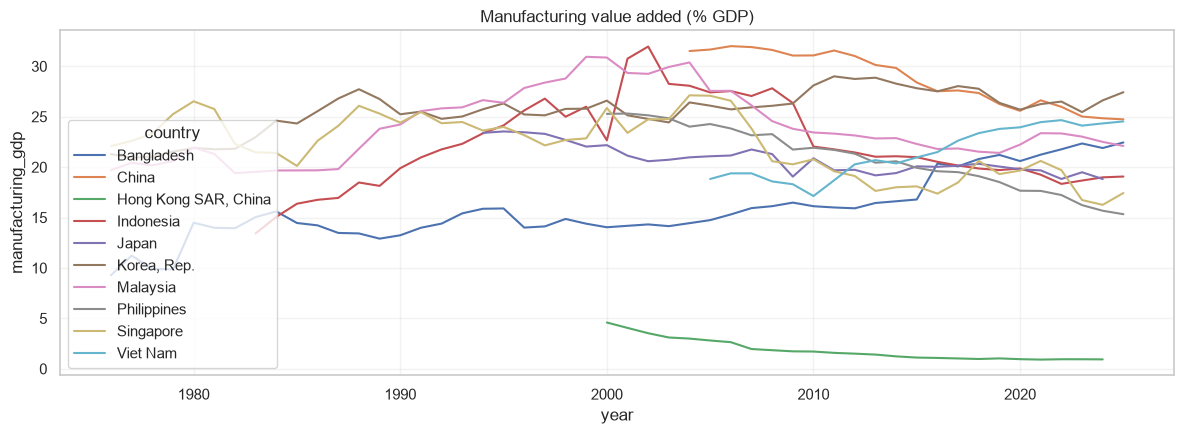

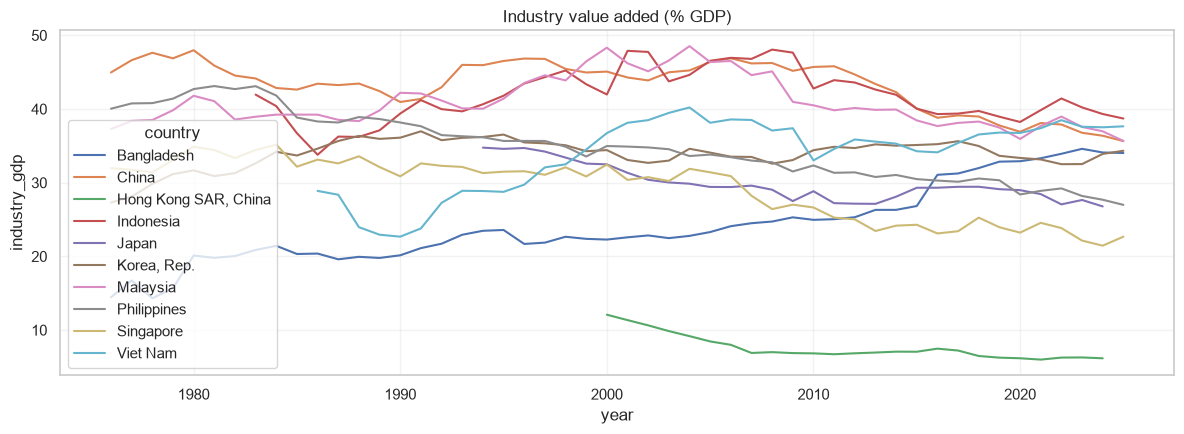

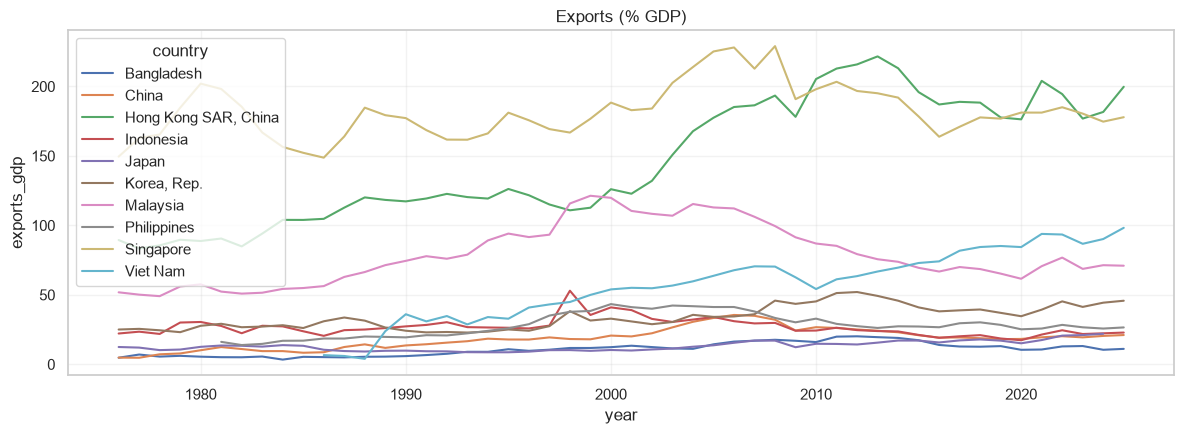

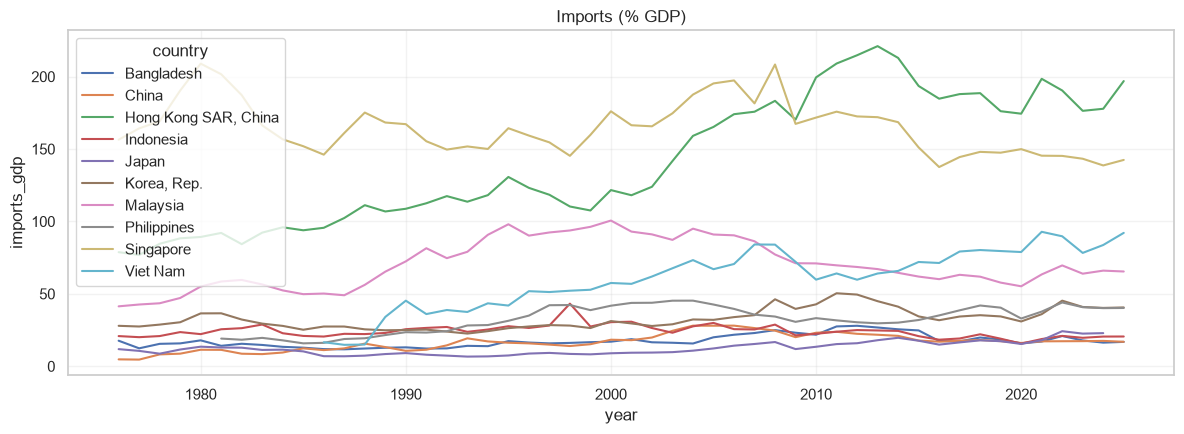

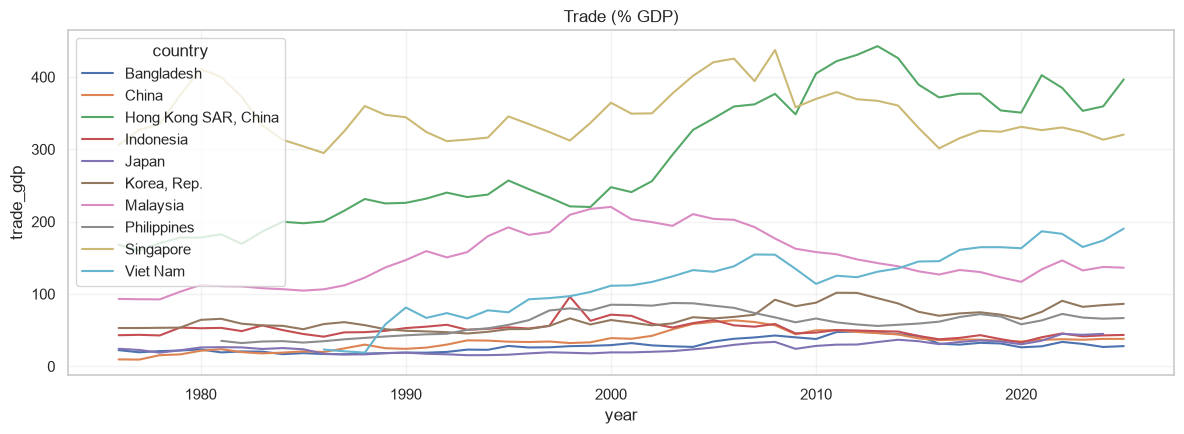

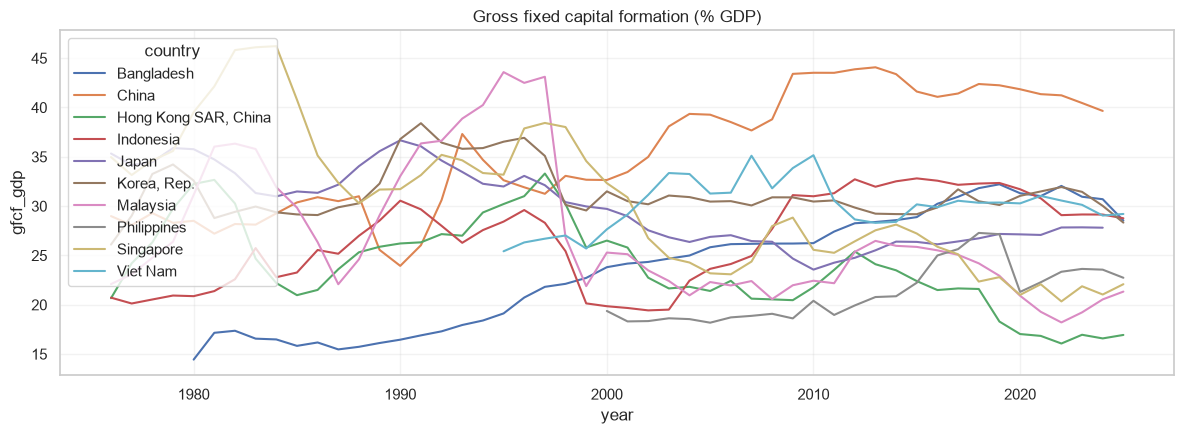

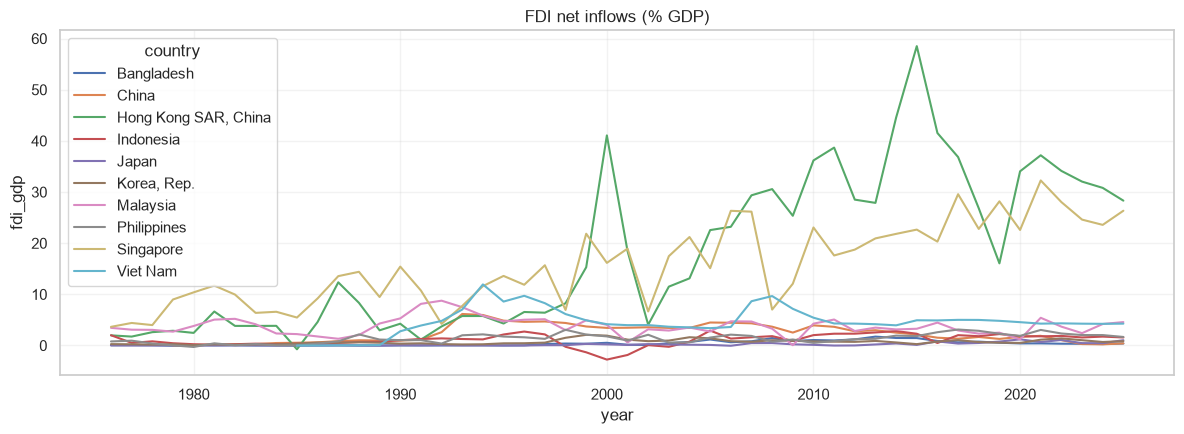

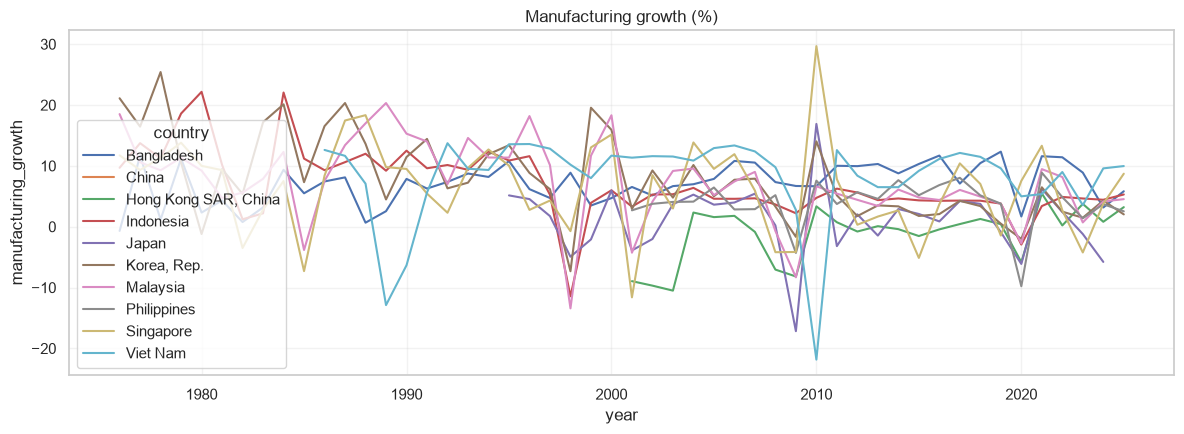

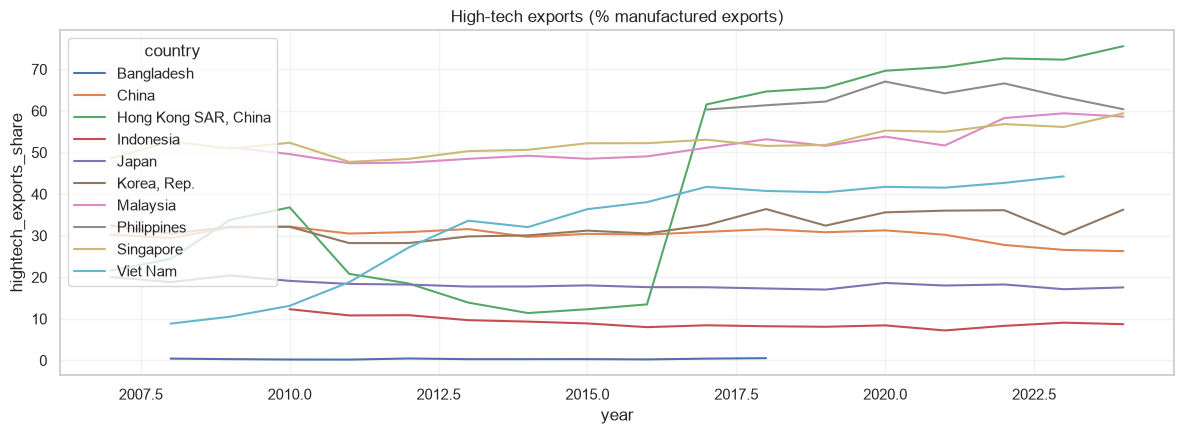

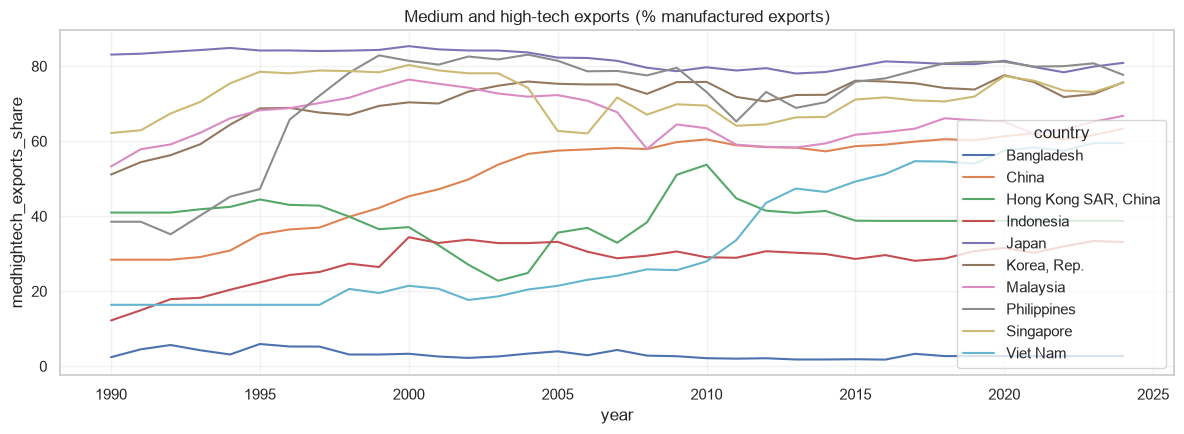

In [2]:
specs=[('manufacturing_gdp','Manufacturing value added (% GDP)'),('industry_gdp','Industry value added (% GDP)'),('exports_gdp','Exports (% GDP)'),('imports_gdp','Imports (% GDP)'),('trade_gdp','Trade (% GDP)'),('gfcf_gdp','Gross fixed capital formation (% GDP)'),('fdi_gdp','FDI net inflows (% GDP)'),('manufacturing_growth','Manufacturing growth (%)'),('hightech_exports_share','High-tech exports (% manufactured exports)'),('medhightech_exports_share','Medium and high-tech exports (% manufactured exports)')]
for v,title in specs:
 if v not in panel or panel[v].notna().sum()==0: print('Unavailable:',v); continue
 fig,ax=plt.subplots(figsize=(12,4.5)); sns.lineplot(data=panel,x='year',y=v,hue='country',ax=ax); ax.set_title(title); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 2. Common-window comparisons and trend tests

Endpoint changes use overlapping observed years. Spearman tests identify monotonic trends, not causes. Benjamini–Hochberg controls false-discovery rate across tests.

In [3]:
variables=[v for v,_ in specs if v in panel]; rows=[]
for v in variables:
 bd=panel.loc[panel.country.eq('Bangladesh'),['year',v]].dropna().rename(columns={v:'BD'})
 for peer in sorted(set(panel.country)-{'Bangladesh'}):
  q=panel.loc[panel.country.eq(peer),['year',v]].dropna().rename(columns={v:'peer'}); z=bd.merge(q,on='year').sort_values('year')
  if len(z): rows.append({'indicator':v,'peer':peer,'n_common':len(z),'first_year':int(z.year.min()),'last_year':int(z.year.max()),'BD_change':z.BD.iloc[-1]-z.BD.iloc[0],'peer_change':z.peer.iloc[-1]-z.peer.iloc[0]})
common=pd.DataFrame(rows); display(common.round(3))
tr=[]
for country in sorted(panel.country.unique()):
 for v in variables:
  z=panel.loc[panel.country.eq(country),['year',v]].dropna()
  if len(z)>=10:
   rho,p=stats.spearmanr(z.year,z[v]); tr.append({'country':country,'indicator':v,'n':len(z),'start':int(z.year.min()),'end':int(z.year.max()),'slope_per_year':np.polyfit(z.year,z[v],1)[0],'rho':rho,'p_raw':p})
trends=pd.DataFrame(tr); trends['p_BH']=multipletests(trends.p_raw,method='fdr_bh')[1]; display(trends.sort_values('p_BH').round(4))

,indicator,peer,n_common,first_year,last_year,BD_change,peer_change
0,manufacturing_gdp,China,22,2004,2025,7.999,-6.776
1,manufacturing_gdp,"Hong Kong SAR, China",25,2000,2024,7.858,-3.656
2,manufacturing_gdp,Indonesia,43,1983,2025,7.398,5.637
3,manufacturing_gdp,Japan,31,1994,2024,6.024,-4.577
4,manufacturing_gdp,"Korea, Rep.",50,1976,2025,13.157,6.140
...,...,...,...,...,...,...,...
84,medhightech_exports_share,"Korea, Rep.",35,1990,2024,0.294,24.609
85,medhightech_exports_share,Malaysia,35,1990,2024,0.294,13.511
86,medhightech_exports_share,Philippines,35,1990,2024,0.294,39.138
87,medhightech_exports_share,Singapore,35,1990,2024,0.294,13.418


,country,indicator,n,start,end,slope_per_year,rho,p_raw,p_BH
70,Philippines,industry_gdp,50,1976,2025,-0.3024,-0.9845,0.0000,0.0000
1,Bangladesh,industry_gdp,50,1976,2025,0.3363,0.9659,0.0000,0.0000
69,Philippines,manufacturing_gdp,26,2000,2025,-0.4056,-0.9966,0.0000,0.0000
5,Bangladesh,gfcf_gdp,46,1980,2025,0.4179,0.9642,0.0000,0.0000
97,Viet Nam,medhightech_exports_share,35,1990,2024,1.5369,0.9797,0.0000,0.0000
...,...,...,...,...,...,...,...,...,...
30,Indonesia,industry_gdp,43,1983,2025,0.0393,0.0601,0.7018,0.7317
29,Indonesia,manufacturing_gdp,43,1983,2025,0.0269,0.0551,0.7255,0.7485
54,"Korea, Rep.",gfcf_gdp,50,1976,2025,-0.0293,-0.0209,0.8855,0.9040
76,Philippines,manufacturing_growth,25,2001,2025,-0.0265,0.0138,0.9476,0.9574


## 3. Structural breaks and two-way fixed effects

Break scans are exploratory segmented-trend tests with at least 10 observations per regime and Bonferroni correction across candidate dates within each series. Fixed-effects coefficients are associations, not causal effects; ten clusters is a small base for cluster-robust inference.

In [4]:
def scan_break(z,v,min_side=10):
 z=z[['year',v]].dropna().sort_values('year').copy()
 if len(z)<2*min_side+3:return pd.DataFrame()
 out=[]
 for yr in sorted(z.year.unique())[min_side-1:-min_side]:
  q=z.copy(); q['t']=q.year-q.year.min(); q['post']=(q.year>yr).astype(int); q['tpost']=q.t*q.post
  fit=smf.ols(f'Q(\"{v}\") ~ t + post + tpost',data=q).fit(cov_type='HC3'); w=fit.wald_test('post=0, tpost=0',scalar=True)
  out.append({'break_year':int(yr),'p_raw':float(w.pvalue),'n_pre':int((q.year<=yr).sum()),'n_post':int((q.year>yr).sum())})
 r=pd.DataFrame(out)
 if len(r):r['p_Bonferroni']=multipletests(r.p_raw,method='bonferroni')[1]
 return r
br=[]
for c in sorted(panel.country.unique()):
 for v in ['manufacturing_gdp','exports_gdp','imports_gdp','gfcf_gdp','fdi_gdp','medhightech_exports_share']:
  if v not in panel:continue
  r=scan_break(panel[panel.country.eq(c)],v)
  if len(r):
   x=r.loc[r.p_raw.idxmin()].to_dict();x.update(country=c,indicator=v,n=int(panel.loc[panel.country.eq(c),v].notna().sum()));br.append(x)
breaks=pd.DataFrame(br); display(breaks.sort_values('p_Bonferroni').round(4) if len(breaks) else 'No eligible series')
for v in ['fdi_gdp','gfcf_gdp','exports_gdp','imports_gdp','manufacturing_gdp']:
 if v in panel:panel[v+'_lag1']=panel.groupby('iso3')[v].shift(1)
reg=[]
for y,xs in [('manufacturing_gdp',['fdi_gdp_lag1','gfcf_gdp_lag1','exports_gdp_lag1']),('exports_gdp',['manufacturing_gdp_lag1','fdi_gdp_lag1','gfcf_gdp_lag1']),('gfcf_gdp',['fdi_gdp_lag1','manufacturing_gdp_lag1'])]:
 z=panel[[y]+xs+['iso3','year']].dropna()
 if len(z)>50 and z.iso3.nunique()>=5:
  m=smf.ols(f'{y} ~ '+' + '.join(xs)+' + C(iso3) + C(year)',data=z).fit(cov_type='cluster',cov_kwds={'groups':z.iso3})
  for x in xs:reg.append({'outcome':y,'predictor':x,'coef':m.params[x],'se_cluster':m.bse[x],'p_raw':m.pvalues[x],'n':int(m.nobs),'countries':z.iso3.nunique()})
reg=pd.DataFrame(reg)
if len(reg):reg['p_BH']=multipletests(reg.p_raw,method='fdr_bh')[1]
display(reg.round(4))

,break_year,p_raw,n_pre,n_post,p_Bonferroni,country,indicator,n
17,1995.0,0.0000,13.0,30.0,0.0000,Indonesia,manufacturing_gdp,43
10,2003.0,0.0000,14.0,21.0,0.0000,China,medhightech_exports_share,35
9,1992.0,0.0000,14.0,33.0,0.0000,China,fdi_gdp,47
37,2000.0,0.0000,25.0,25.0,0.0000,Malaysia,imports_gdp,50
36,1997.0,0.0000,22.0,28.0,0.0000,Malaysia,exports_gdp,50
8,2008.0,0.0000,33.0,16.0,0.0000,China,gfcf_gdp,49
42,1999.0,0.0000,19.0,26.0,0.0000,Philippines,exports_gdp,45
35,2004.0,0.0000,29.0,21.0,0.0000,Malaysia,manufacturing_gdp,50
57,2010.0,0.0000,21.0,14.0,0.0000,Viet Nam,medhightech_exports_share,35
40,2000.0,0.0000,11.0,24.0,0.0000,Malaysia,medhightech_exports_share,35


,outcome,predictor,coef,se_cluster,p_raw,n,countries,p_BH
0,manufacturing_gdp,fdi_gdp_lag1,-0.1531,0.0664,0.0212,359,10,0.0424
1,manufacturing_gdp,gfcf_gdp_lag1,0.1300,0.0739,0.0785,359,10,0.1046
2,manufacturing_gdp,exports_gdp_lag1,0.0844,0.0276,0.0022,359,10,0.0088
3,exports_gdp,manufacturing_gdp_lag1,2.0525,0.9364,0.0284,355,10,0.0454
4,exports_gdp,fdi_gdp_lag1,0.6187,0.1743,0.0004,355,10,0.0031
5,exports_gdp,gfcf_gdp_lag1,-0.5416,0.2009,0.0070,355,10,0.0187
6,gfcf_gdp,fdi_gdp_lag1,-0.1850,0.1895,0.3291,355,10,0.3291
7,gfcf_gdp,manufacturing_gdp_lag1,0.3441,0.2748,0.2105,355,10,0.2406


## 4. Stationarity, cross-country dependence and lead/lag

ADF null: unit root. KPSS null: stationarity. These are univariate tests, not panel unit-root tests. The dependence statistic is approximate and should not be reported as a validated Pesaran CD test. Lead/lag correlations do not prove a product transfer or causal baton pass.

In [5]:
st=[]
for c in sorted(panel.country.unique()):
 for v in ['manufacturing_gdp','exports_gdp','imports_gdp','fdi_gdp','gfcf_gdp','manufacturing_growth','medhightech_exports_share']:
  if v not in panel:continue
  q=panel.loc[panel.country.eq(c),['year',v]].dropna().sort_values('year')[v].astype(float)
  if len(q)<15:continue
  for form,x in [('level',q),('first_difference',q.diff().dropna())]:
   if len(x)<12:continue
   try:a=adfuller(x,autolag='AIC',regression='ct' if form=='level' else 'c')[1]
   except Exception:a=np.nan
   try:k=kpss(x,regression='ct' if form=='level' else 'c',nlags='auto')[1]
   except Exception:k=np.nan
   st.append({'country':c,'indicator':v,'form':form,'n':len(x),'ADF_p':a,'KPSS_p':k})
stationarity=pd.DataFrame(st); display(stationarity.round(4))
def cd_approx(v):
 w=panel.pivot(index='year',columns='country',values=v); w=w.loc[w.notna().sum(axis=1)>=5]; w=w.loc[:,w.notna().sum(axis=0)>=10]
 if w.shape[0]<10 or w.shape[1]<5:return {'indicator':v,'N':w.shape[1],'T':w.shape[0],'CD_approx':np.nan,'p_approx':np.nan}
 corr=w.corr(min_periods=10); vals=corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().dropna();N,T=w.shape;cd=np.sqrt(2*T/(N*(N-1)))*vals.sum()
 return {'indicator':v,'N':N,'T':T,'CD_approx':cd,'p_approx':2*stats.norm.sf(abs(cd)),'mean_pair_corr':vals.mean(),'pairs':len(vals)}
cd=pd.DataFrame([cd_approx(v) for v in ['manufacturing_gdp','exports_gdp','imports_gdp','fdi_gdp','gfcf_gdp','manufacturing_growth','medhightech_exports_share'] if v in panel]);cd['p_BH']=multipletests(cd.p_approx.fillna(1),method='fdr_bh')[1];display(cd.round(4))
ll=[]
for v in ['manufacturing_gdp','exports_gdp','hightech_exports_share','medhightech_exports_share','gfcf_gdp']:
 if v not in panel:continue
 for peer in ['China','Korea, Rep.','Viet Nam','Malaysia','Hong Kong SAR, China']:
  if peer not in set(panel.country):continue
  for lag in [0,5,10]:
   for form in ['levels','annual_change']:
    a=panel[panel.country.eq('Bangladesh')].set_index('year')[v];b=panel[panel.country.eq(peer)].set_index('year')[v]
    if form=='annual_change':a=a.diff();b=b.diff()
    z=pd.concat([a.rename('bd'),b.rename('peer')],axis=1);z['lagged_peer']=z.peer.shift(lag);z=z[['bd','lagged_peer']].dropna()
    if len(z)>=12:
     rho,p=stats.spearmanr(z.bd,z.lagged_peer);ll.append({'indicator':v,'peer':peer,'lag':lag,'form':form,'n':len(z),'rho':rho,'p_raw':p})
leadlag=pd.DataFrame(ll)
if len(leadlag):leadlag['p_BH']=multipletests(leadlag.p_raw,method='fdr_bh')[1];display(leadlag.sort_values('p_BH').round(4))

,country,indicator,form,n,ADF_p,KPSS_p
0,Bangladesh,manufacturing_gdp,level,50,0.4401,0.0280
1,Bangladesh,manufacturing_gdp,first_difference,49,0.0000,0.1000
2,Bangladesh,exports_gdp,level,50,0.9402,0.0308
3,Bangladesh,exports_gdp,first_difference,49,0.0000,0.1000
4,Bangladesh,imports_gdp,level,50,0.4326,0.0919
...,...,...,...,...,...,...
133,Viet Nam,gfcf_gdp,first_difference,30,0.0000,0.1000
134,Viet Nam,manufacturing_growth,level,40,0.0021,0.1000
135,Viet Nam,manufacturing_growth,first_difference,39,0.0000,0.1000
136,Viet Nam,medhightech_exports_share,level,35,0.1376,0.0288


,indicator,N,T,CD_approx,p_approx,mean_pair_corr,pairs,p_BH
0,manufacturing_gdp,43,10,0.5221,0.6016,0.1103,45,0.7018
1,exports_gdp,50,10,1.7772,0.0755,0.4371,45,0.5287
2,imports_gdp,50,10,1.3174,0.1877,0.3240,45,0.6485
3,fdi_gdp,50,10,0.9669,0.3336,0.2378,45,0.6485
4,gfcf_gdp,50,10,-0.0955,0.9239,-0.0235,45,0.9239
5,manufacturing_growth,50,9,0.8954,0.3706,0.2902,36,0.6485
6,medhightech_exports_share,35,10,0.5870,0.5572,0.1006,45,0.7018


,indicator,peer,lag,form,n,rho,p_raw,p_BH
29,exports_gdp,China,5,levels,45,0.9159,0.0000,0.0000
89,gfcf_gdp,China,5,levels,45,0.9088,0.0000,0.0000
87,gfcf_gdp,China,0,levels,45,0.8846,0.0000,0.0000
27,exports_gdp,China,0,levels,50,0.8597,0.0000,0.0000
91,gfcf_gdp,China,10,levels,40,0.8962,0.0000,0.0000
...,...,...,...,...,...,...,...,...
95,gfcf_gdp,"Korea, Rep.",5,levels,45,-0.0174,0.9097,0.9962
94,gfcf_gdp,"Korea, Rep.",0,annual_change,45,0.0024,0.9877,0.9962
92,gfcf_gdp,China,10,annual_change,39,-0.0132,0.9366,0.9962
110,gfcf_gdp,Malaysia,10,annual_change,39,-0.0160,0.9230,0.9962


## 5. Interpretation and next research step

The WDI aggregates can assess industrial deepening, trade integration and investment accumulation, but not the product-level Flying Geese mechanism. A cautious conclusion is “partially consistent with, but insufficient to establish, the Flying Geese hypothesis.” See `flying_geese_findings.md` for numerical findings and limitations.

For a decisive test, add HS product-level trade from [UN Comtrade](https://comtradeplus.un.org/) or [CEPII BACI](https://www.cepii.fr/CEPII/en/bdd_modele/presentation.asp?id=37), then estimate revealed comparative advantage, export diversification and product entry/exit. For subsector output/employment, consider [UNIDO INDSTAT](https://stat.unido.org/).